# Confirm the layer-32 scoring settings on the test split, once

Notebook 12 re-selected the scoring settings for the layer-32 predictors on synthetic validation data only and saved them in `results/improvements/layer32_synthetic_val/selected_settings.json` (selected: `maha_d128`, `sigma 0`, `k = 1`, `lambda 1`, default `tau`). This notebook reads that record and evaluates **exactly that configuration** on the official test split a single time. **Nothing is tuned here**: there is no loop over settings, the grid is not extended, and the notebook stops if the record says the test split influenced the choice, if it was already applied to test, or if it does not hold the `maha_d128` configuration this notebook implements. The hash of the record is checked before and after the run.

**Rows scored on the test split (each exactly once)**

| Key | Predictor / features | Scoring | Image score |
| --- | --- | --- | --- |
| `selected` | layer-32 predictor | **Mahalanobis residual, d = 128**, statistics fitted on **all nominal validation images only** (coarse-window residuals, ridge 1e-3, as notebooks 05 to 07) | `raw_image_score` (max fused patch score; Mahalanobis scores are unbounded, so the bounded `image_score` is undefined) |
| `l32 cosine` | same layer-32 predictor | `1 - cos` | `raw_image_score` (max); **identical windows, gate, `tau`, `lambda`, upsampling and metrics** to `selected`, so the only difference is the per-token score |
| `l32 notebook 11` | same layer-32 predictor | per-position z-score (statistics from nominal validation images), as reported in notebook 11 | top-3 mean (notebook 11's headline), max also shown |
| `original` | final-layer baseline predictors | `1 - cos`, adaptive, default `tau`, max score | `raw_image_score` (max) |

**Comparisons (paired bootstrap, 95%, 1,000 resamples, seed 0; good and anomalous images resampled separately; the same resamples for every comparison within a category)**

1. **Primary, isolates the scoring change:** `selected` vs `l32 cosine`, both max.
2. **vs the notebook 11 configuration.** It differs in the score family *and* in `k` (top-3 vs max), which is labelled in every row. Two like-for-like diagnostics separate the two differences: both at top-3, and both at max.
3. **Historical:** `selected` vs `original` (final-layer baseline, max). This mixes the layer, the retrained predictor and the scoring change. `l32 cosine` vs `original` is shown only as context for how much of that is the layer.

Pixel AUROC and AUPRO are point estimates (no interval). Masks per image and scorer latency are measured on the same run. The fine pass is gated on the baseline `1 - cos` region scores in all layer-32 rows, so `selected` and `l32 cosine` evaluate the same windows.

**Consistency checks against saved results (they reproduce earlier rows; they do not feed any setting):** `original` against notebook 07's baseline row, and `l32 cosine` / `l32 notebook 11` against notebook 11's saved rows (tolerance 1e-4).

## 1. Configuration and the saved selection

In [1]:
import hashlib
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image

try:
    display
except NameError:
    display = print

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next((p for p in candidates if (p / 'configs').is_dir() and (p / 'src').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
LAYER = 32
ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
SELECTION_PATH = PROJECT_ROOT / 'results' / 'improvements' / 'layer32_synthetic_val' / 'selected_settings.json'
SETS = {
    'final': {'predictors': PROJECT_ROOT / 'checkpoints' / 'predictors', 'train_root': PROJECT_ROOT / 'data' / 'cache' / 'latents',
              'test_root': PROJECT_ROOT / 'data' / 'cache' / 'latents_test', 'encoder_name': 'ijepa_vit_g16_in22k_ep44'},
    'layer 32': {'predictors': PROJECT_ROOT / 'checkpoints' / f'predictors_layer{LAYER}', 'train_root': PROJECT_ROOT / 'data' / 'cache' / f'latents_layer{LAYER}',
                 'test_root': PROJECT_ROOT / 'data' / 'cache' / f'latents_layer{LAYER}_test', 'encoder_name': f'ijepa_vit_g16_in22k_ep44_layer{LAYER}'},
}
OUTPUT_ROOT = Path(os.environ.get('LAYER32_CONFIRMATION_OUTPUT', PROJECT_ROOT / 'results' / 'improvements' / 'layer32_confirmation'))
OVERWRITE = False
OUTPUT_FILES = ('layer32_confirmation_metrics.csv', 'bootstrap_deltas.csv', 'point_estimate_deltas.csv', 'reproduction_checks.csv', 'layer32_confirmation_summary.json')
MASKING_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'masking' / 'coarse_to_fine.yaml'
DATA_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml').read_text(encoding='utf-8'))
VAL_FRACTION, SPLIT_SEED = float(DATA_CONFIG['nominal_split']['val_fraction']), int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
N_BOOTSTRAP, BOOTSTRAP_SEED = 1000, 0
# fitting choices declared (not tuned) in notebooks 05 and 06
POSITION_STD_FLOOR_FRACTION, MAHA_RIDGE = 0.5, 1e-3
K11 = 3                                                     # notebook 11's top-k, used only to reproduce its row

if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()]
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)) + ' (set OVERWRITE = True)')


def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


SELECTION_SHA256_BEFORE = sha256_of(SELECTION_PATH)
selection = json.loads(SELECTION_PATH.read_text(encoding='utf-8'))
if selection['test_used_for_selection'] is not False or selection['test_split_read'] is not False:
    raise ValueError('The selection record says the test split was used.')
if selection['not_applied_to_test'] is not True:
    raise ValueError('The selection record says it was already applied to the test split; this notebook is the one-time confirmation.')
SELECTED = selection['selected_settings']
EXPECTED = {'family': 'maha_d128', 'sigma': 0.0, 'k': 1, 'lam': 1.0, 'tau': 'default'}
if SELECTED != EXPECTED:
    raise ValueError(f'This notebook implements {EXPECTED}; the saved selection is {SELECTED}. Stopping, nothing is re-selected here.')
MAHA_COMPONENTS = int(SELECTED['family'][len('maha_d'):])
print('selected settings (authoritative, from', SELECTION_PATH.relative_to(PROJECT_ROOT), '):', SELECTED)
print('selection record sha256:', SELECTION_SHA256_BEFORE)

selected settings (authoritative, from results\improvements\layer32_synthetic_val\selected_settings.json ): {'family': 'maha_d128', 'k': 1, 'lam': 1.0, 'sigma': 0.0, 'tau': 'default'}
selection record sha256: 9782602dc3511bda53be184635c2b391fb335e7df4285f0ba3eb6aa04d5e28e4


In [2]:
from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.data.mvtec_dataset import validate_category_splits
from ijepa_ad.data.splits import split_nominal_train_val
from ijepa_ad.data.transforms import PreprocessConfig
from ijepa_ad.evaluation.metrics import aupro, image_auroc, pixel_auroc
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.inference import MaskedLatentScorer, load_masking_settings, load_predictor_checkpoint_with_provenance
from ijepa_ad.masking.score_maps import upsample_patch_scores
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset
from ijepa_ad.scoring import PositionNormaliser, fit_mahalanobis_residual

REAL_SHA = compute_file_sha256(ENCODER_CHECKPOINT)
IDENTITY = {'final': REAL_SHA, 'layer 32': hashlib.sha256(f'{REAL_SHA}|layer={LAYER}|token_layer_norm|v1'.encode()).hexdigest()}
if IDENTITY['layer 32'] != selection['provenance']['layer_identity_sha256'] or REAL_SHA != selection['provenance']['encoder_checkpoint_sha256']:
    raise ValueError('encoder / layer-32 identity differs from the one in the selection record')
MASKING_SETTINGS = load_masking_settings(MASKING_CONFIG_PATH)
DEFAULT_TAU, LAM_DEFAULT = MASKING_SETTINGS['threshold'], MASKING_SETTINGS['lam']
if float(SELECTED['lam']) != LAM_DEFAULT:
    raise ValueError('selected lambda differs from the configured lambda')
SPEC = PreprocessingSpec.from_config(PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size'])))


def expectations(set_name, category, split, samples):
    return CacheExpectations(category=category, split=split, encoder_name=SETS[set_name]['encoder_name'], checkpoint_sha256=IDENTITY[set_name],
                             patch_size=PATCH_SIZE, embedding_dim=EMBEDDING_DIM, preprocessing=SPEC,
                             sample_ids=tuple(s.image_id for s in samples), num_tokens=NUM_TOKENS)


def load_ground_truth(annotation):
    if annotation.mask_path is None:
        with Image.open(annotation.image_path) as image:
            width, height = image.size
        return np.zeros((height, width), dtype=bool)
    with Image.open(annotation.mask_path) as mask_image:
        return np.asarray(mask_image.convert('L')) > 0


PREDICTORS, TRAIN, VAL, TESTSET, TEST, PREDICTOR_SHA = {}, {}, {}, {}, {}, {}
for category in CATEGORIES:
    root = next(r for r in (PROJECT_ROOT / DATA_CONFIG['root'], PROJECT_ROOT / 'dataset', PROJECT_ROOT / 'dataset' / category) if (r / category / 'train').is_dir())
    train_ds, test_ds = validate_category_splits(root, category)
    nominal = split_nominal_train_val(train_ds.samples, val_fraction=VAL_FRACTION, seed=SPLIT_SEED,
                                      min_train=int(DATA_CONFIG['nominal_split']['min_train']), min_val=int(DATA_CONFIG['nominal_split']['min_val']))
    for name, cfg in SETS.items():
        VAL[(name, category)] = load_cached_latent_dataset(cfg['train_root'], expectations(name, category, 'val', nominal.val), samples=train_ds.samples)
        TESTSET[(name, category)] = load_cached_latent_dataset(cfg['test_root'], expectations(name, category, 'test', test_ds.samples), samples=test_ds.samples)
        path = cfg['predictors'] / f'{category}_cosine.pt'
        PREDICTORS[(name, category)], prov = load_predictor_checkpoint_with_provenance(path, category=category, encoder_sha256=IDENTITY[name], device=DEVICE)
        PREDICTOR_SHA[(name, category)] = compute_file_sha256(path)
        print(f'{name:>9} / {category}: val={len(VAL[(name, category)])}, test={len(TESTSET[(name, category)])}, predictor {prov["status"]}/{prov["mask_strategy"]}')
    if PREDICTOR_SHA[('layer 32', category)] != selection['provenance']['predictor_sha256'][category]:
        raise ValueError(f'{category}: layer-32 predictor file differs from the one the selection was made with')
    ref = TESTSET[('final', category)]
    if list(TESTSET[('layer 32', category)].sample_ids) != list(ref.sample_ids):
        raise ValueError(f'{category}: test image order differs between the final-layer and layer-32 caches')
    TEST[category] = {'labels': np.asarray([int(s.annotation.label != 'good') for s in ref]), 'masks': [load_ground_truth(s.annotation) for s in ref]}
print('layer-32 predictors are byte-identical to the ones used for the selection (sha256 in the record)')

    final / bottle: val=21, test=83, predictor complete/inference_aligned
 layer 32 / bottle: val=21, test=83, predictor complete/inference_aligned
    final / capsule: val=22, test=132, predictor complete/inference_aligned
 layer 32 / capsule: val=22, test=132, predictor complete/inference_aligned
    final / hazelnut: val=39, test=110, predictor complete/inference_aligned
 layer 32 / hazelnut: val=39, test=110, predictor complete/inference_aligned
layer-32 predictors are byte-identical to the ones used for the selection (sha256 in the record)


## 2. Fit statistics on nominal validation data, then score the test split once per row

`run_scorer` is the loop of notebooks 05, 07 and 11. It is called **once per row on the test set** (counted and asserted); validation passes only fit statistics. The Mahalanobis model is fitted on the coarse-window residuals `actual - predicted` of **all nominal validation images** of the category (no test data, no synthetic data). The image score of the Mahalanobis row is read from `InferenceResult.raw_image_score`, and is checked to equal the maximum of the fused patch scores used for the pixel maps.

In [3]:
TEST_PASSES = {}


def run_scorer(predictor, dataset, mode, *, discrepancy=None, timed=False, row=None):
    scorer = MaskedLatentScorer(predictor, discrepancy=discrepancy, **MASKING_SETTINGS)
    if row is not None:
        TEST_PASSES[row] = TEST_PASSES.get(row, 0) + 1
    if timed:
        scorer.score(dataset[0].latent.unsqueeze(0).to(DEVICE), mode=mode)           # warm-up, not counted
    coarse, fine, raw, work, seconds = [], [], [], [], 0.0
    for sample in dataset:
        latent = sample.latent.unsqueeze(0).to(DEVICE)
        if timed and DEVICE == 'cuda':
            torch.cuda.synchronize()
        tick = time.perf_counter()
        result = scorer.score(latent, mode=mode)
        if timed and DEVICE == 'cuda':
            torch.cuda.synchronize()
        seconds += time.perf_counter() - tick
        coarse.append(result.coarse_scores.detach().cpu()); fine.append(result.fine_scores.detach().cpu())
        raw.append(result.raw_image_score); work.append(result.evaluated_regions)
    return {'coarse': torch.stack(coarse), 'fine': torch.stack(fine), 'raw': np.asarray(raw), 'work': np.asarray(work),
            'ms': 1000 * seconds / len(dataset), 'scorer': scorer}


def region_scores(scorer, coarse):
    out = torch.zeros_like(coarse)
    for window in scorer.coarse.windows():
        idx = list(window.token_indices)
        out[:, idx] = coarse[:, idx].mean(dim=1, keepdim=True)
    return out


def fit_mahalanobis(predictor, dataset, components):
    scorer0 = MaskedLatentScorer(predictor, **MASKING_SETTINGS)
    windows = scorer0.coarse.windows()
    residuals = torch.cat([
        (s.latent.unsqueeze(0).to(DEVICE).float() - scorer0.window_predictions(s.latent.unsqueeze(0).to(DEVICE), windows).float()).cpu()[0]
        for s in dataset
    ])
    return fit_mahalanobis_residual(residuals, n_components=components, ridge=MAHA_RIDGE), residuals.shape[0]


ROW_KEYS = ('original', 'l32 cosine', 'l32 notebook 11', 'selected')
ROWS = {}            # (category, key) -> dict(patch, raw, work, ms, ...)
FIT_INFO = {}
for category in CATEGORIES:
    started = time.perf_counter()
    # ---- original project baseline: final-layer predictor, 1 - cos, adaptive, default tau ----
    orig = run_scorer(PREDICTORS[('final', category)], TESTSET[('final', category)], 'adaptive', timed=True, row=(category, 'original'))
    assert np.allclose(orig['raw'], (orig['coarse'] + LAM_DEFAULT * orig['fine']).max(dim=1).values.numpy(), rtol=1e-5, atol=1e-5)
    ROWS[(category, 'original')] = {'patch': orig['coarse'] + LAM_DEFAULT * orig['fine'], 'raw': orig['raw'], 'work': orig['work'], 'ms': orig['ms'], 'ms_note': 'timed adaptive scorer'}

    predictor, test, val = PREDICTORS[('layer 32', category)], TESTSET[('layer 32', category)], VAL[('layer 32', category)]
    # ---- layer-32 predictor, raw cosine: the like-for-like reference ----
    base = run_scorer(predictor, test, 'adaptive', timed=True, row=(category, 'l32 cosine'))
    assert np.allclose(base['raw'], (base['coarse'] + LAM_DEFAULT * base['fine']).max(dim=1).values.numpy(), rtol=1e-5, atol=1e-5)
    ROWS[(category, 'l32 cosine')] = {'patch': base['coarse'] + LAM_DEFAULT * base['fine'], 'raw': base['raw'], 'work': base['work'], 'ms': base['ms'], 'ms_note': 'timed adaptive scorer'}

    # ---- notebook 11 configuration: per-position z-score from nominal validation, post hoc on the adaptive pass above (no second test pass) ----
    val_c = run_scorer(predictor, val, 'fixed')['coarse']
    val_f = run_scorer(predictor, val, 'dense')['fine']
    norm_c = PositionNormaliser.fit(val_c, divide=True, std_floor_fraction=POSITION_STD_FLOOR_FRACTION)
    norm_f = PositionNormaliser.fit(val_f, divide=True, std_floor_fraction=POSITION_STD_FLOOR_FRACTION)
    fired = region_scores(base['scorer'], base['coarse']) >= DEFAULT_TAU
    TEST_PASSES[(category, 'l32 notebook 11')] = TEST_PASSES[(category, 'l32 cosine')]      # derived from that single pass
    patch11 = norm_c.apply(base['coarse']) + LAM_DEFAULT * fired.float() * norm_f.apply(base['fine'])
    ROWS[(category, 'l32 notebook 11')] = {'patch': patch11, 'raw': patch11.max(dim=1).values.numpy(), 'work': base['work'], 'ms': base['ms'],
                                           'ms_note': 'same adaptive scorer pass as l32 cosine; the post hoc z-score is a per-token affine op and is not timed'}

    # ---- selected: Mahalanobis d = 128, statistics from all nominal validation images ----
    maha, n_tokens = fit_mahalanobis(predictor, val, MAHA_COMPONENTS)
    FIT_INFO[category] = {'mahalanobis_fit_images': len(val), 'mahalanobis_fit_tokens': int(n_tokens), 'components': MAHA_COMPONENTS, 'ridge': MAHA_RIDGE}
    sel = run_scorer(predictor, test, 'adaptive', discrepancy=maha, timed=True, row=(category, 'selected'))
    patch_sel = sel['coarse'] + float(SELECTED['lam']) * sel['fine']
    if not np.allclose(sel['raw'], patch_sel.max(dim=1).values.numpy(), rtol=1e-5, atol=1e-5):
        raise AssertionError(f'{category}: raw_image_score differs from the max of the fused patch scores')
    ROWS[(category, 'selected')] = {'patch': patch_sel, 'raw': sel['raw'], 'work': sel['work'], 'ms': sel['ms'], 'ms_note': 'timed adaptive scorer including the Mahalanobis discrepancy'}
    print(f'{category}: {time.perf_counter() - started:.0f}s; masks/image original {orig["work"].mean():.2f}, l32 cosine {base["work"].mean():.2f}, selected {sel["work"].mean():.2f}')

passes = {k: v for k, v in TEST_PASSES.items()}
assert all(v == 1 for k, v in passes.items() if k[1] != 'l32 notebook 11') and len(passes) == len(CATEGORIES) * len(ROW_KEYS), passes
print('each test row was scored by exactly one scorer pass:', {k[1] for k in passes})

C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\.venv\Lib\site-packages\torch\nn\modules\transformer.py:685: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._transformer_encoder_layer_fwd(


bottle: 16s; masks/image original 16.19, l32 cosine 16.19, selected 16.19
capsule: 21s; masks/image original 16.00, l32 cosine 16.00, selected 16.00
hazelnut: 24s; masks/image original 16.15, l32 cosine 16.58, selected 16.58
each test row was scored by exactly one scorer pass: {'original', 'selected', 'l32 notebook 11', 'l32 cosine'}


## 3. Metrics

Image AUROC uses the `raw_image_score` (max) for `original`, `l32 cosine` and `selected`; the notebook 11 row is shown with its top-3 mean (its reported headline) and with its max. The `selected` row's top-3 mean is also computed, as a **diagnostic only** (the selected `k` is 1 and is not changed). Pixel maps are the patch scores upsampled straight to the ground-truth size; AUPRO uses 200 thresholds (as in notebooks 05, 07 and 11).

In [4]:
def metrics_for(category, key):
    labels, masks = TEST[category]['labels'], TEST[category]['masks']
    row = ROWS[(category, key)]
    patch = row['patch']
    maps = [upsample_patch_scores(p, output_size=m.shape)[0, 0].numpy().astype(np.float32) for p, m in zip(patch, masks)]
    return {'scores': {'max': row['raw'], 'top3': patch.topk(K11, dim=1).values.mean(dim=1).numpy()},
            'pixel_auroc': pixel_auroc(maps, masks), 'aupro': aupro(maps, masks, num_thresholds=200)}


RESULTS = {}
for category in CATEGORIES:
    started = time.perf_counter()
    for key in ROW_KEYS:
        RESULTS[(category, key)] = metrics_for(category, key)
    print(f'{category}: evaluated in {time.perf_counter() - started:.0f}s')

DESCRIPTION = {
    'original': 'final-layer baseline predictor, 1 - cos, max (historical baseline)',
    'l32 cosine': 'layer-32 predictor, 1 - cos, max (like-for-like reference)',
    'l32 notebook 11': 'layer-32 predictor, per-position z-score, top-3 (notebook 11 headline; max also shown)',
    'selected': 'layer-32 predictor, Mahalanobis d=128, max = raw_image_score (this selection)',
}
metric_rows = []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    for key in ROW_KEYS:
        r, row = RESULTS[(category, key)], ROWS[(category, key)]
        metric_rows.append({'category': category, 'row': key, 'description': DESCRIPTION[key],
                            'image_auroc_max': image_auroc(labels, r['scores']['max']), 'image_auroc_top3': image_auroc(labels, r['scores']['top3']),
                            'pixel_auroc': r['pixel_auroc'], 'aupro': r['aupro'], 'masks_per_image': float(row['work'].mean()),
                            'scorer_ms_per_image': row['ms'], 'latency_note': row['ms_note']})
metrics_df = pd.DataFrame(metric_rows)
for category in CATEGORIES:
    print(category)
    display(metrics_df[metrics_df.category == category].drop(columns=['category', 'description', 'latency_note']).round(4).reset_index(drop=True))

# ---- consistency with saved results (reproduction checks; they feed nothing) ----
saved07 = pd.read_csv(PROJECT_ROOT / 'results' / 'improvements' / 'confirmation' / 'selected_vs_baseline.csv')
saved11 = pd.read_csv(PROJECT_ROOT / 'results' / 'improvements' / 'layer_predictor' / 'layer_predictor_metrics.csv')
CHECKS, ok = [], True
for category in CATEGORIES:
    mine = lambda key: metrics_df[(metrics_df.category == category) & (metrics_df.row == key)].iloc[0]
    pairs = (('original', saved07[(saved07.category == category) & (saved07.config == 'baseline')].iloc[0]),
             ('l32 cosine', saved11[(saved11.category == category) & (saved11.row == 'layer 32 / baseline score')].iloc[0]),
             ('l32 notebook 11', saved11[(saved11.category == category) & (saved11.row == 'layer 32 / selected')].iloc[0]))
    for key, saved_row in pairs:
        cols = ['image_auroc_max', 'pixel_auroc', 'aupro'] + (['image_auroc_top3'] if key == 'l32 notebook 11' else [])
        diffs = {c: abs(float(mine(key)[c]) - float(saved_row[c if c != 'image_auroc_top3' else f'image_auroc_top{K11}'])) for c in cols}
        passed = all(v < 1e-4 for v in diffs.values())
        ok &= passed
        CHECKS.append({'category': category, 'row': key, 'max_abs_diff': max(diffs.values()), 'passed': passed})
checks_df = pd.DataFrame(CHECKS)
display(checks_df.round(6))
REPRODUCES_SAVED = bool(ok)
print('earlier rows reproduced from saved results:', REPRODUCES_SAVED)
if not REPRODUCES_SAVED:
    raise AssertionError('A reference row does not reproduce its saved value; stopping before the comparison is reported.')

bottle: evaluated in 78s
capsule: evaluated in 121s
hazelnut: evaluated in 87s
bottle


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,original,0.9246,0.9516,0.9295,0.7657,16.1928,33.1627
1,l32 cosine,0.9587,0.9754,0.9791,0.9043,16.1928,32.0090
2,l32 notebook 11,0.9937,0.9992,0.9660,0.8714,16.1928,32.0090
3,selected,0.9913,0.9976,0.9830,0.9278,16.1928,32.7256


capsule


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,original,0.5217,0.5122,0.6845,0.0981,16.0,31.5444
1,l32 cosine,0.5429,0.6598,0.8357,0.3090,16.0,31.5085
2,l32 notebook 11,0.7208,0.7675,0.9307,0.6663,16.0,31.5085
3,selected,0.6003,0.6466,0.9564,0.7200,16.0,34.3019


hazelnut


,row,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,masks_per_image,scorer_ms_per_image
0,original,0.8021,0.8975,0.9067,0.5774,16.1455,32.3769
1,l32 cosine,0.9464,0.9893,0.9861,0.8768,16.5818,32.5270
2,l32 notebook 11,0.9814,0.9932,0.9888,0.9013,16.5818,32.5270
3,selected,0.9596,0.9689,0.9873,0.8938,16.5818,33.0157


,category,row,max_abs_diff,passed
0,bottle,original,0.0,True
1,bottle,l32 cosine,0.0,True
2,bottle,l32 notebook 11,0.0,True
3,capsule,original,0.0,True
4,capsule,l32 cosine,0.0,True
5,capsule,l32 notebook 11,0.0,True
6,hazelnut,original,0.0,True
7,hazelnut,l32 cosine,0.0,True
8,hazelnut,l32 notebook 11,0.0,True


earlier rows reproduced from saved results: True


## 4. Paired bootstrap on image AUROC

One set of 1,000 resamples per category (good and anomalous images resampled separately, seed 0), reused for every comparison, so the deltas are paired and comparable. Verdict: `improves` if the whole 95% interval is above 0, `worsens` if it is below, otherwise `inconclusive`.

In [5]:
def bootstrap_indices(labels):
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    pos, neg = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)
    return [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(N_BOOTSTRAP)]


def verdict(low, high):
    return 'improves' if low > 0 else 'worsens' if high < 0 else 'inconclusive (CI contains 0)'


COMPARISONS = (
    ('1 PRIMARY: scoring change only (layer 32, same windows)', ('selected', 'max', 'selected, Mahalanobis d=128, max'), ('l32 cosine', 'max', 'layer 32, 1 - cos, max')),
    ('2a vs notebook 11 as reported (family AND k differ: z-score top-3)', ('selected', 'max', 'selected, Mahalanobis d=128, max'), ('l32 notebook 11', 'top3', 'notebook 11, z-score, top-3')),
    ('2b vs notebook 11, same score k=3 (family differs; selected top-3 is a diagnostic)', ('selected', 'top3', 'selected, Mahalanobis d=128, top-3'), ('l32 notebook 11', 'top3', 'notebook 11, z-score, top-3')),
    ('2c vs notebook 11, same score k=1 (family differs)', ('selected', 'max', 'selected, Mahalanobis d=128, max'), ('l32 notebook 11', 'max', 'notebook 11, z-score, max')),
    ('3 HISTORICAL: vs original baseline (layer + predictor + scoring all differ)', ('selected', 'max', 'selected, Mahalanobis d=128, max'), ('original', 'max', 'original baseline, final layer, 1 - cos, max')),
    ('context: layer effect alone, layer 32 cosine vs original', ('l32 cosine', 'max', 'layer 32, 1 - cos, max'), ('original', 'max', 'original baseline, final layer, 1 - cos, max')),
)
boot_rows, point_rows = [], []
for category in CATEGORIES:
    labels = TEST[category]['labels']
    indices = bootstrap_indices(labels)
    for label, (k1, s1, d1), (k2, s2, d2) in COMPARISONS:
        new, ref = RESULTS[(category, k1)]['scores'][s1], RESULTS[(category, k2)]['scores'][s2]
        deltas = np.asarray([image_auroc(labels[i], new[i]) - image_auroc(labels[i], ref[i]) for i in indices])
        low, high = np.percentile(deltas, [2.5, 97.5])
        boot_rows.append({'category': category, 'comparison': label, 'new': d1, 'reference': d2, 'image_auroc': image_auroc(labels, new), 'reference_auroc': image_auroc(labels, ref),
                          'delta_image_auroc': image_auroc(labels, new) - image_auroc(labels, ref), 'ci95_low': low, 'ci95_high': high, 'verdict': verdict(low, high)})
        a, b = RESULTS[(category, k1)], RESULTS[(category, k2)]
        point_rows.append({'category': category, 'comparison': label, 'delta_pixel_auroc': a['pixel_auroc'] - b['pixel_auroc'], 'delta_aupro': a['aupro'] - b['aupro'],
                           'delta_masks_per_image': float(ROWS[(category, k1)]['work'].mean() - ROWS[(category, k2)]['work'].mean()),
                           'delta_scorer_ms': float(ROWS[(category, k1)]['ms'] - ROWS[(category, k2)]['ms'])})
boot_df, point_df = pd.DataFrame(boot_rows), pd.DataFrame(point_rows)
shown = boot_df.copy()
shown['CI95'] = shown.apply(lambda r: f'[{r.ci95_low:+.3f}, {r.ci95_high:+.3f}]', axis=1)
for label, *_ in COMPARISONS:
    print(label)
    display(shown[shown.comparison == label][['category', 'image_auroc', 'reference_auroc', 'delta_image_auroc', 'CI95', 'verdict']].round(4).reset_index(drop=True))
print('Point-estimate deltas (no interval):')
display(point_df.round(4))

1 PRIMARY: scoring change only (layer 32, same windows)


,category,image_auroc,reference_auroc,delta_image_auroc,CI95,verdict
0,bottle,0.9913,0.9587,0.0325,"[+0.004, +0.078]",improves
1,capsule,0.6003,0.5429,0.0574,"[-0.123, +0.259]",inconclusive (CI contains 0)
2,hazelnut,0.9596,0.9464,0.0132,"[-0.031, +0.068]",inconclusive (CI contains 0)


2a vs notebook 11 as reported (family AND k differ: z-score top-3)


,category,image_auroc,reference_auroc,delta_image_auroc,CI95,verdict
0,bottle,0.9913,0.9992,-0.0079,"[-0.029, +0.002]",inconclusive (CI contains 0)
1,capsule,0.6003,0.7675,-0.1671,"[-0.282, -0.057]",worsens
2,hazelnut,0.9596,0.9932,-0.0336,"[-0.067, -0.007]",worsens


2b vs notebook 11, same score k=3 (family differs; selected top-3 is a diagnostic)


,category,image_auroc,reference_auroc,delta_image_auroc,CI95,verdict
0,bottle,0.9976,0.9992,-0.0016,"[-0.010, +0.003]",inconclusive (CI contains 0)
1,capsule,0.6466,0.7675,-0.1209,"[-0.229, -0.016]",worsens
2,hazelnut,0.9689,0.9932,-0.0243,"[-0.054, -0.001]",worsens


... (4 outputs left out)

context: layer effect alone, layer 32 cosine vs original


,category,image_auroc,reference_auroc,delta_image_auroc,CI95,verdict
0,bottle,0.9587,0.9246,0.0341,"[-0.024, +0.110]",inconclusive (CI contains 0)
1,capsule,0.5429,0.5217,0.0211,"[-0.075, +0.114]",inconclusive (CI contains 0)
2,hazelnut,0.9464,0.8021,0.1443,"[+0.061, +0.239]",improves


Point-estimate deltas (no interval):


,category,comparison,delta_pixel_auroc,delta_aupro,delta_masks_per_image,delta_scorer_ms
0,bottle,"1 PRIMARY: scoring change only (layer 32, same...",0.0038,0.0235,0.0000,0.7166
1,bottle,2a vs notebook 11 as reported (family AND k di...,0.0170,0.0564,0.0000,0.7166
2,bottle,"2b vs notebook 11, same score k=3 (family diff...",0.0170,0.0564,0.0000,0.7166
3,bottle,"2c vs notebook 11, same score k=1 (family diff...",0.0170,0.0564,0.0000,0.7166
4,bottle,3 HISTORICAL: vs original baseline (layer + pr...,0.0534,0.1621,0.0000,-0.4371
5,bottle,"context: layer effect alone, layer 32 cosine v...",0.0496,0.1386,0.0000,-1.1538
6,capsule,"1 PRIMARY: scoring change only (layer 32, same...",0.1207,0.4110,0.0000,2.7935
7,capsule,2a vs notebook 11 as reported (family AND k di...,0.0257,0.0537,0.0000,2.7935
8,capsule,"2b vs notebook 11, same score k=3 (family diff...",0.0257,0.0537,0.0000,2.7935
9,capsule,"2c vs notebook 11, same score k=1 (family diff...",0.0257,0.0537,0.0000,2.7935


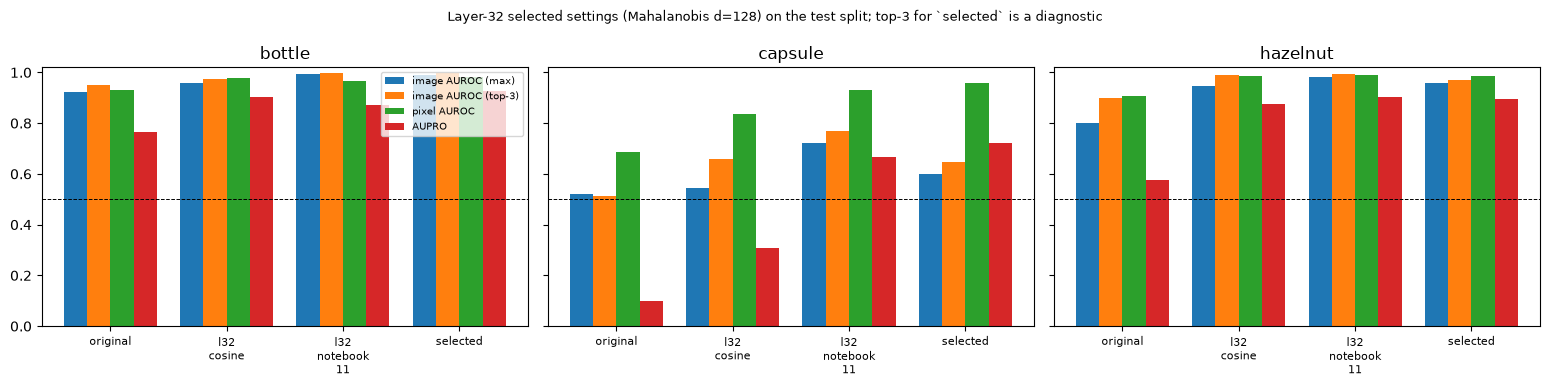

In [6]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(5.2 * len(CATEGORIES), 3.9), sharey=True)
width = 0.2
for ax, category in zip(np.atleast_1d(axes), CATEGORIES):
    view = metrics_df[metrics_df.category == category].set_index('row')
    for offset, (col, label) in enumerate((('image_auroc_max', 'image AUROC (max)'), ('image_auroc_top3', 'image AUROC (top-3)'), ('pixel_auroc', 'pixel AUROC'), ('aupro', 'AUPRO'))):
        ax.bar(np.arange(len(ROW_KEYS)) + (offset - 1.5) * width, [view.loc[k, col] for k in ROW_KEYS], width, label=label)
    ax.set_xticks(range(len(ROW_KEYS)))
    ax.set_xticklabels([k.replace(' ', '\n') for k in ROW_KEYS], fontsize=8)
    ax.set_title(category); ax.axhline(0.5, color='black', linewidth=0.7, linestyle='--'); ax.set_ylim(0, 1.02)
np.atleast_1d(axes)[0].legend(fontsize=7)
fig.suptitle('Layer-32 selected settings (Mahalanobis d=128) on the test split; top-3 for `selected` is a diagnostic', fontsize=9)
fig.tight_layout()
plt.show()

## 5. Save

The record file must be byte-identical to what was read at the start.

In [7]:
SELECTION_SHA256_AFTER = sha256_of(SELECTION_PATH)
if SELECTION_SHA256_AFTER != SELECTION_SHA256_BEFORE:
    raise AssertionError('the selection record changed during this notebook')


def git_state():
    def run(*args):
        try:
            return subprocess.run(['git', *args], cwd=PROJECT_ROOT, capture_output=True, text=True, check=False).stdout.strip()
        except OSError:
            return ''
    return {'head': run('rev-parse', 'HEAD') or 'unavailable', 'dirty_files': len(run('status', '--porcelain').splitlines())}


OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / 'figures').mkdir(exist_ok=True)
if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()] + list((OUTPUT_ROOT / 'figures').glob('*.png'))
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)))
metrics_df.to_csv(OUTPUT_ROOT / 'layer32_confirmation_metrics.csv', index=False)
boot_df.to_csv(OUTPUT_ROOT / 'bootstrap_deltas.csv', index=False)
point_df.to_csv(OUTPUT_ROOT / 'point_estimate_deltas.csv', index=False)
checks_df.to_csv(OUTPUT_ROOT / 'reproduction_checks.csv', index=False)
fig.savefig(OUTPUT_ROOT / 'figures' / 'layer32_confirmation.png', dpi=150, bbox_inches='tight')
primary = boot_df[boot_df.comparison.str.startswith('1 PRIMARY')].set_index('category')
(OUTPUT_ROOT / 'layer32_confirmation_summary.json').write_text(json.dumps({
    'selection_file': str(SELECTION_PATH.relative_to(PROJECT_ROOT)), 'selection_sha256': SELECTION_SHA256_BEFORE, 'selection_unchanged_during_run': True,
    'selected_settings': SELECTED, 'chosen_from': selection['chosen_from'],
    'test_used_for_selection': False,
    'test_split_scored': 'once per row (original, l32 cosine, selected; the notebook 11 row is derived from the l32 cosine pass); no setting was changed or added after seeing test numbers',
    'image_score': 'raw_image_score (max fused patch score) for original, l32 cosine and selected (Mahalanobis scores are unbounded); top-3 is a diagnostic only',
    'statistics_fitted_on': 'all nominal validation images of each category (Mahalanobis: coarse-window residuals; z-score for the notebook 11 row): no test, no synthetic data',
    'fit_info': FIT_INFO, 'bootstrap': {'n': N_BOOTSTRAP, 'seed': BOOTSTRAP_SEED, 'resampling': 'good and anomalous test images separately; same resamples for every comparison within a category'},
    'comparisons': [c[0] for c in COMPARISONS],
    'reference_rows_reproduce_saved_results': REPRODUCES_SAVED, 'predictor_sha256': {f'{n}/{c}': v for (n, c), v in PREDICTOR_SHA.items()},
    'primary_verdicts': primary.verdict.to_dict(), 'primary_delta_image_auroc': primary.delta_image_auroc.round(4).to_dict(),
    'git': git_state(), 'torch': torch.__version__, 'device': DEVICE,
}, indent=2, sort_keys=True, default=str), encoding='utf-8')
print('saved to', OUTPUT_ROOT)

saved to C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\layer32_confirmation


## What you can and cannot say

**You can say**

* The layer-32 scoring configuration was selected on synthetic validation data before this evaluation (record hash checked), its statistics were fitted on nominal validation images only, and each test row was scored once.
* The effect of the **scoring change alone** (Mahalanobis d = 128 versus `1 - cos` on the same layer-32 predictor, same windows, same max image score), with a paired-bootstrap interval, plus point estimates for pixel AUROC and AUPRO.
* How the selected configuration relates to notebook 11's reported configuration, **with the score family and `k` differences labelled**, and to the original baseline (a historical comparison in which the layer, the retrained predictor and the scoring all differ).

**You cannot say**

* That an interval containing 0 shows an improvement or a harm.
* That the selected configuration is the best possible: only the notebook 06 grid was searched, and ties go to the simpler option. `d = 128` is the largest value in the grid.
* That the gain over the original baseline is due to the scoring change: it is mostly the layer and the retrained predictor, as the layer-32 cosine row shows.
* Anything about other seeds (each predictor is one training run), other categories, or other encoder layers or mask sizes.
* That the top-3 diagnostic row is a recommended setting: the selected `k` is 1.